# 🔬 Семестровый проект по машинному обучению
## Диагностика новообразований молочной железы (Wisconsin Diagnostic Breast Cancer)
### 📌 Первая аттестация: Недели 1–8

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

---

### 📋 Содержание
1. [Неделя 1: Введение в ML и Постановка задачи (Problem Statement)](#week1)
2. [Неделя 2: Pandas и первичный анализ данных (Dataset Description)](#week2)
3. [Неделя 3: Исследовательский анализ данных (Exploratory Data Analysis — EDA)](#week3)
4. [Неделя 4: Предобработка данных (Data Preprocessing)](#week4)
5. [Неделя 5: Разделение выборки и выбор метрик (Train/Test Split & Metrics)](#week5)
6. [Неделя 6: Базовые модели (Baseline: DummyClassifier & Logistic Regression)](#week6)
7. [Неделя 7: Деревья решений и сравнение моделей (Decision Tree & Random Forest)](#week7)
8. [Неделя 8: Итоги 1-й аттестации, выводы и Шпаргалка к защите (Defense Guide)](#week8)


In [1]:
# Импорт всех необходимых библиотек
import os
import sys
import warnings
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn: подготовка данных и валидация
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Sklearn: модели классификации
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Sklearn: метрики качества
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, ConfusionMatrixDisplay
)

# Настройка визуализаций
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("✓ Все библиотеки успешно импортированы!")


✓ Все библиотеки успешно импортированы!


<a id="week1"></a>
## 🎯 Неделя 1: Введение в ML и Постановка задачи

### 1.1. Описание предметной области
Рак молочной железы (РМЖ) является самым распространенным онкологическим заболеванием среди женщин во всем мире. Ранняя диагностика имеет решающее значение: пятилетняя выживаемость при обнаружении опухоли на I стадии превышает **95%**, тогда как на IV стадии снижается до **25-30%**.

Одним из основных малоинвазивных методов первичного обследования является **тонкоигольная аспирационная пункционная биопсия (Fine Needle Aspirate, FNA)**. Полученные микропрепараты оцифровываются, после чего по компьютерным изображениям ядер клеток рассчитываются геометрические и текстурные характеристики.

### 1.2. Постановка ML-задачи
* **Тип задачи:** Бинарная классификация с учителем (Supervised Binary Classification).
* **Входные данные ($X$):** Вектор из 30 вещественных признаков, описывающих форму, размер и текстуру ядер клеток опухоли.
* **Целевая переменная ($y$):** Диагноз опухоли:
  * **$0$ (Benign, B)** — Доброкачественная опухоль.
  * **$1$ (Malignant, M)** — Злокачественная опухоль (рак).

### 1.3. Практическая ценность и цена ошибок в медицине
Разрабатываемая модель предназначена для использования в **Клинических системах поддержки принятия врачебных решений (CDSS)**. Автоматизация позволяет ускорить постановку диагноза и снизить влияние человеческого фактора (усталость патоморфолога).

В медицинской диагностике цена ошибок асимметрична:
* **Ложноположительная ошибка (False Positive, FP — Ошибка I рода):** Модель классифицирует доброкачественную опухоль как злокачественную. Последствия: пациентка направляется на углубленное обследование (МРТ, повторная трепан-биопсия), испытывает психологический стресс, однако ее жизни ничего непосредственно не угрожает.
* **Ложноотрицательная ошибка (False Negative, FN — Ошибка II рода):** Модель принимает раковую опухоль за доброкачественную и "отпускает" пациента домой. Последствия: болезнь прогрессирует без терапии, появляются метастазы, что ведет к **необратимому ухудшению здоровья или летальному исходу**.

> 💡 **Ключевой методологический вывод:** Главной целевой метрикой проекта является **Recall (Полнота)** по классу злокачественных новообразований ($M=1$) при сохранении высокого уровня **ROC-AUC** и приемлемого **Precision**.


<a id="week2"></a>
## 📂 Неделя 2: Pandas и первичный анализ данных

### 2.1. Описание датасета (Wisconsin Diagnostic Breast Cancer — WDBC)
* **Источник данных:** [UCI Machine Learning Repository: Breast Cancer Wisconsin (Diagnostic)](https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+(Diagnostic))
* **Авторы:** Dr. William H. Wolberg, W. Nick Street, Olvi L. Mangasarian (University of Wisconsin, Madison, 1995).
* **Объем выборки:** 569 пациентов.
* **Признаковое пространство:** 30 количественных характеристик, полученных по оцифрованным снимкам клеток FNA.
  * Вычисляются 10 базовых морфологических признаков:
    1. *radius* — среднее расстояние от центра до точек периметра
    2. *texture* — стандартное отклонение значений серой шкалы
    3. *perimeter* — периметр ядра
    4. *area* — площадь ядра
    5. *smoothness* — локальная вариация длин радиусов
    6. *compactness* — компактность ($	ext{perimeter}^2 / 	ext{area} - 1.0$)
    7. *concavity* — степень выраженности вогнутых участков контура
    8. *concave points* — количество вогнутых участков контура
    9. *symmetry* — симметрия ядра
    10. *fractal dimension* — фрактальная размерность ("приближение береговой линии" - 1)
  * Для каждого изображения вычислены:
    * **mean** (среднее значение по ядрам в кадре): признаки 1–10
    * **se** (стандартная ошибка среднего): признаки 11–20
    * **worst** (наихудшее / среднее из 3 наибольших значений): признаки 21–30


In [2]:
# Определение имен столбцов в строгом соответствии с документацией wdbc.names
feature_bases = [
    'radius', 'texture', 'perimeter', 'area', 'smoothness',
    'compactness', 'concavity', 'concave_points', 'symmetry', 'fractal_dimension'
]

feature_names = (
    [f"{name}_mean" for name in feature_bases] +
    [f"{name}_se" for name in feature_bases] +
    [f"{name}_worst" for name in feature_bases]
)

columns = ['id', 'diagnosis'] + feature_names

# Гибкая загрузка: проверяем локальные пути, а при запуске в Google Colab качаем с UCI
data_paths = [
    'dataset/wdbc.data',
    'wdbc.data',
    '../dataset/wdbc.data'
]

df = None
for p in data_paths:
    if os.path.exists(p):
        print(f"Загрузка из локального файла: {p}")
        df = pd.read_csv(p, header=None, names=columns)
        break

if df is None:
    print("Локальный файл не найден (запуск в Google Colab). Загрузка напрямую из репозитория UCI...")
    uci_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
    df = pd.read_csv(uci_url, header=None, names=columns)
    print("✓ Данные успешно загружены из репозитория UCI!")

print(f"Размерность загруженного датасета: {df.shape[0]} строк, {df.shape[1]} колонок")
df.head(5)


Загрузка из локального файла: dataset/wdbc.data
Размерность загруженного датасета: 569 строк, 32 колонок


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
# Проверка структуры данных, типов признаков и наличия пропусков
print("--- Информация о датасете ---")
df.info()

missing_total = df.isnull().sum().sum()
duplicates_total = df.duplicated().sum()

print("\n" + "="*50)
print(f"Общее количество пропущенных значений: {missing_total}")
print(f"Общее количество строк-дубликатов: {duplicates_total}")
print("="*50)


--- Информация о датасете ---
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimet

### 2.2. Анализ целевой переменной `diagnosis`
Проанализируем соотношение классов и оценим наличие дисбаланса.


Распределение целевой переменной:
  [B] Доброкачественные (Benign): 357 пациентов (62.74%)
  [M] Злокачественные (Malignant): 212 пациентов (37.26%)


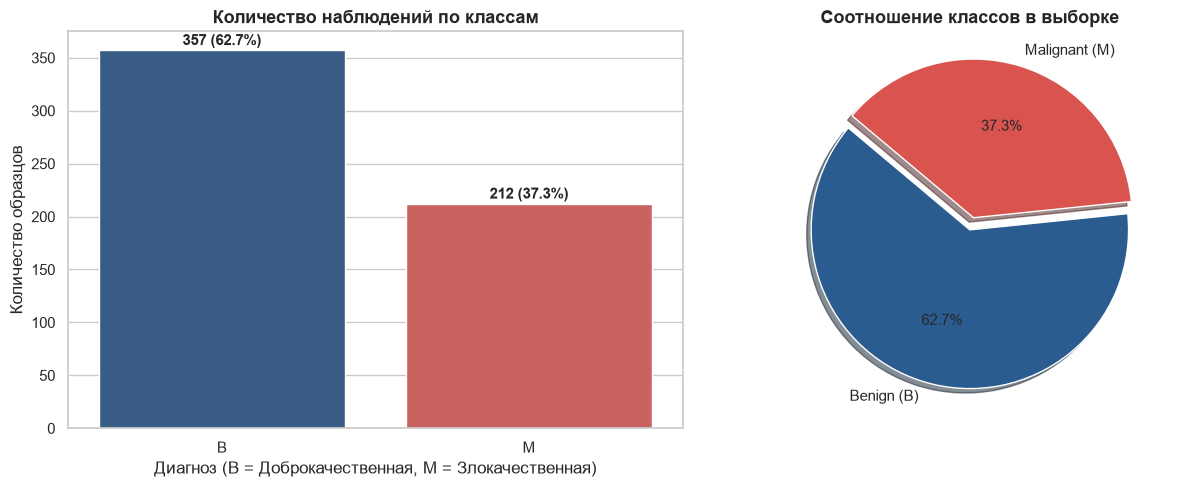

In [4]:
target_counts = df['diagnosis'].value_counts()
target_percent = df['diagnosis'].value_counts(normalize=True) * 100

print("Распределение целевой переменной:")
for label, count, pct in zip(target_counts.index, target_counts, target_percent):
    name = "Доброкачественные (Benign)" if label == 'B' else "Злокачественные (Malignant)"
    print(f"  [{label}] {name}: {count} пациентов ({pct:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Столбчатый график
sns.barplot(x=target_counts.index, y=target_counts.values, ax=axes[0], palette=['#2b5c8f', '#d9534f'])
axes[0].set_title("Количество наблюдений по классам", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Диагноз (B = Доброкачественная, M = Злокачественная)")
axes[0].set_ylabel("Количество образцов")
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 5, f"{v} ({target_percent.values[i]:.1f}%)", ha='center', fontweight='bold')

# Круговая диаграмма
axes[1].pie(
    target_counts.values,
    labels=['Benign (B)', 'Malignant (M)'],
    autopct='%1.1f%%',
    startangle=140,
    colors=['#2b5c8f', '#d9534f'],
    explode=(0, 0.08),
    shadow=True
)
axes[1].set_title("Соотношение классов в выборке", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


**Выводы по целевой переменной:**
* Класс `Benign` составляет **62.74%** (357 наблюдений), класс `Malignant` — **37.26%** (212 наблюдений).
* В выборке наблюдается **умеренный дисбаланс классов** (соотношение приблизительно 1.7 : 1).
* Такой дисбаланс означает, что:
  1. Наивная модель, предсказывающая всегда доброкачественный класс, покажет точность (Accuracy) **62.7%**, будучи абсолютно бесполезной клинически.
  2. При разделении выборки на train и test **необходимо использовать стратификацию (`stratify=y`)**, чтобы сохранить точные пропорции классов в обеих частях.


<a id="week3"></a>
## 📊 Неделя 3: Исследовательский анализ данных (EDA)

### 3.1. Описательная статистика признаков
Изучим основные числовые характеристики: средние, стандартные отклонения, медианы, минимумы и максимумы.


In [5]:
# Описательные статистики для группы признаков _mean
df_mean_features = df[[f"{name}_mean" for name in feature_bases]]
stats = df_mean_features.describe().T[['mean', 'std', 'min', '50%', 'max']]
stats.rename(columns={'50%': 'median'}, inplace=True)
stats['iqr'] = df_mean_features.apply(lambda col: col.quantile(0.75) - col.quantile(0.25))

print("Описательные статистики для признаков группы '_mean':")
stats.round(4)


Описательные статистики для признаков группы '_mean':


,mean,std,min,median,max,iqr
radius_mean,14.1273,3.5240,6.9810,13.3700,28.1100,4.0800
texture_mean,19.2896,4.3010,9.7100,18.8400,39.2800,5.6300
perimeter_mean,91.9690,24.2990,43.7900,86.2400,188.5000,28.9300
area_mean,654.8891,351.9141,143.5000,551.1000,2501.0000,362.4000
smoothness_mean,0.0964,0.0141,0.0526,0.0959,0.1634,0.0189
compactness_mean,0.1043,0.0528,0.0194,0.0926,0.3454,0.0655
concavity_mean,0.0888,0.0797,0.0000,0.0615,0.4268,0.1011
concave_points_mean,0.0489,0.0388,0.0000,0.0335,0.2012,0.0537
symmetry_mean,0.1812,0.0274,0.1060,0.1792,0.3040,0.0338
fractal_dimension_mean,0.0628,0.0071,0.0500,0.0615,0.0974,0.0084


### 3.2. Распределения ключевых признаков по классам
Сравним распределения геометрических и текстурных признаков для доброкачественных и злокачественных клеток с помощью гистограмм и оценок плотности ядра (KDE).


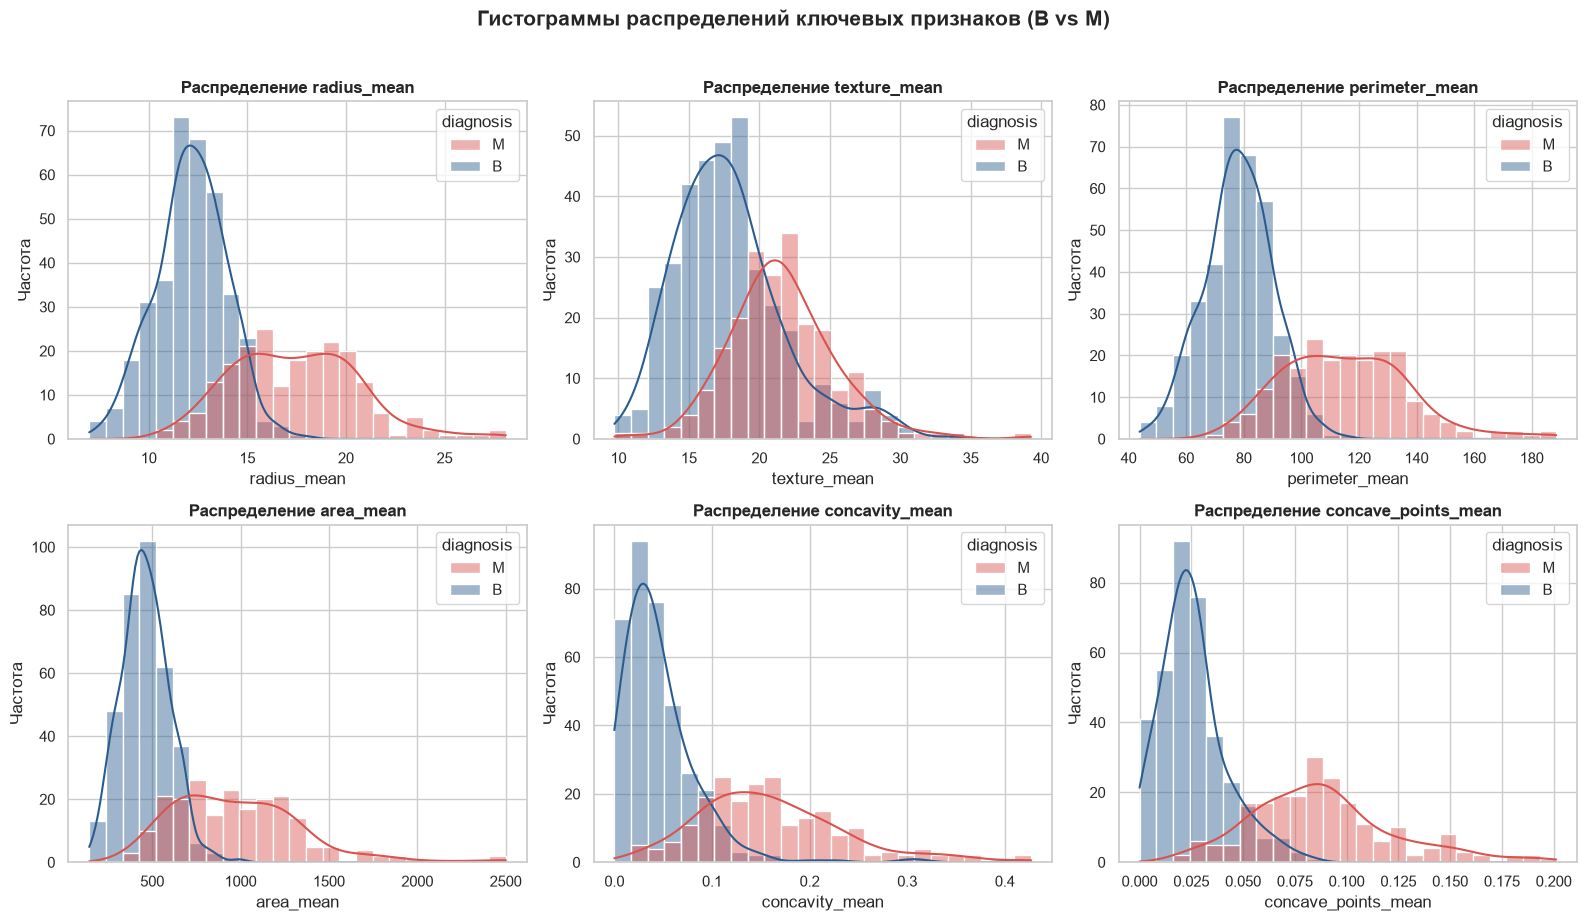

In [6]:
key_features = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'concavity_mean', 'concave_points_mean']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, feat in enumerate(key_features):
    sns.histplot(
        data=df,
        x=feat,
        hue='diagnosis',
        kde=True,
        bins=25,
        ax=axes[i],
        palette={'B': '#2b5c8f', 'M': '#d9534f'},
        alpha=0.45
    )
    axes[i].set_title(f"Распределение {feat}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel("Частота")

plt.suptitle("Гистограммы распределений ключевых признаков (B vs M)", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 3.3. Анализ различий медиан и вариативности (Boxplot)
Boxplot позволяет наглядно оценить межквартильный размах, разделимость классов и наличие потенциальных выбросов.


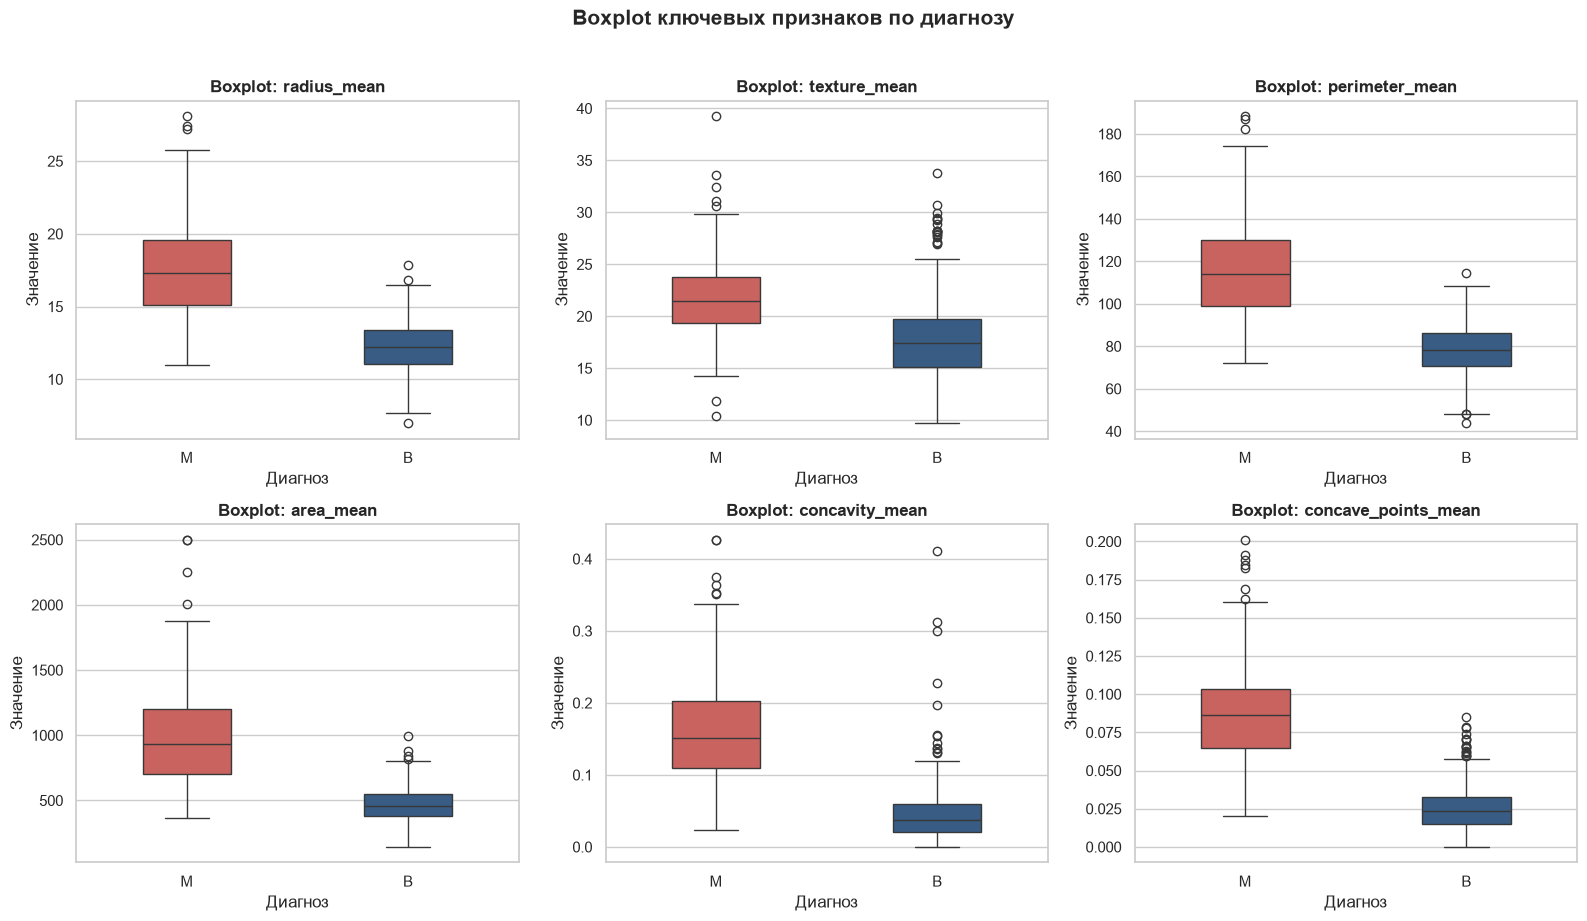

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, feat in enumerate(key_features):
    sns.boxplot(
        data=df,
        x='diagnosis',
        y=feat,
        ax=axes[i],
        palette={'B': '#2b5c8f', 'M': '#d9534f'},
        width=0.4
    )
    axes[i].set_title(f"Boxplot: {feat}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel("Диагноз")
    axes[i].set_ylabel("Значение")

plt.suptitle("Boxplot ключевых признаков по диагнозу", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 3.4. Корреляционный анализ и мультиколлинеарность
Исследуем взаимную корреляцию признаков для обнаружения коллинеарности и оценим их связь с целевой переменной.


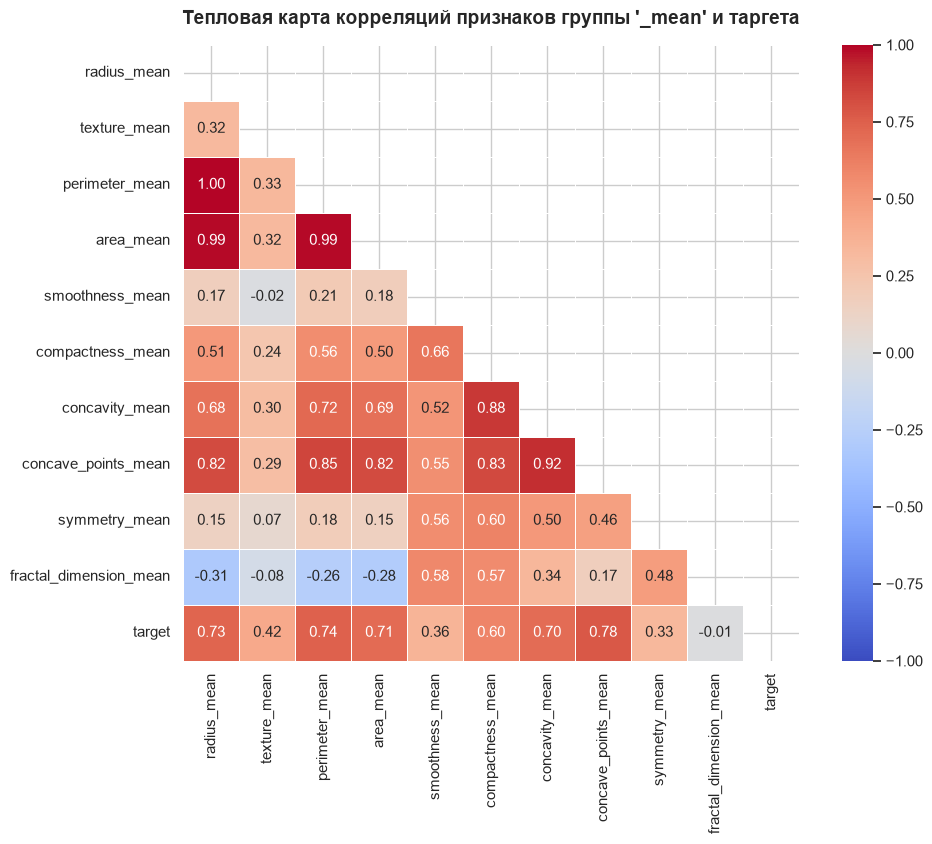

In [8]:
# Преобразуем диагноз в числовую форму для корреляционного анализа (M=1, B=0)
corr_df = df_mean_features.copy()
corr_df['target'] = (df['diagnosis'] == 'M').astype(int)

# Матрица корреляций Пирсона
corr_matrix = corr_df.corr()

plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5
)
plt.title("Тепловая карта корреляций признаков группы '_mean' и таргета", fontsize=14, fontweight='bold', pad=15)
plt.show()


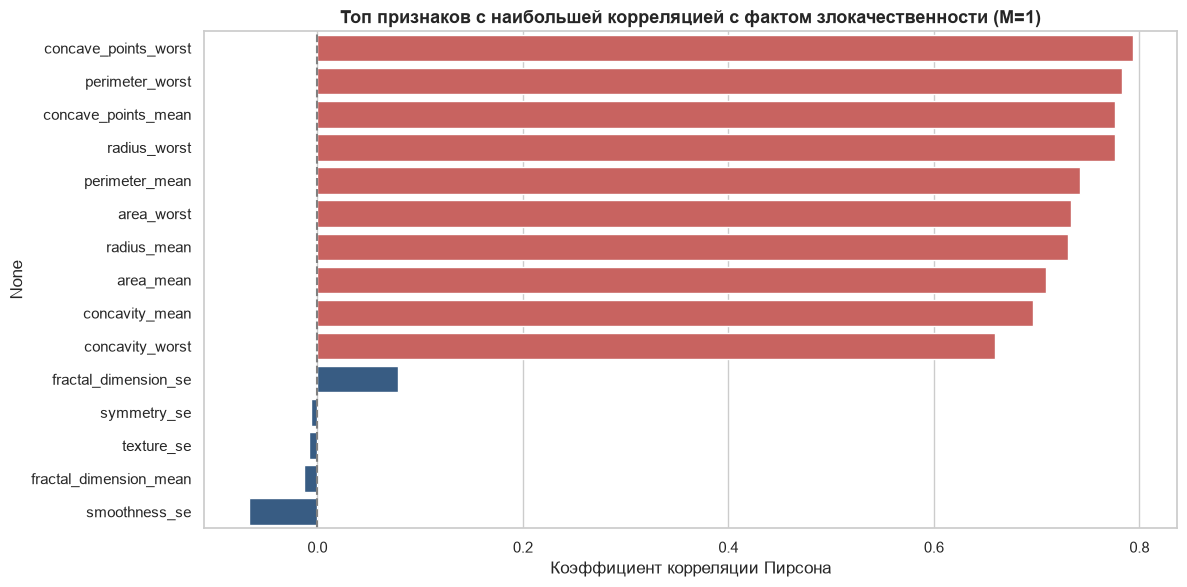

In [9]:
# Корреляция всех 30 признаков с целевой переменной
full_corr = df[feature_names].apply(lambda col: col.corr((df['diagnosis'] == 'M').astype(int)))
top_corr = full_corr.sort_values(ascending=False)

plt.figure(figsize=(12, 6))
top_15_corr = pd.concat([top_corr.head(10), top_corr.tail(5)])
colors = ['#d9534f' if v > 0.5 else '#2b5c8f' for v in top_15_corr.values]

sns.barplot(x=top_15_corr.values, y=top_15_corr.index, palette=colors)
plt.title("Топ признаков с наибольшей корреляцией с фактом злокачественности (M=1)", fontsize=13, fontweight='bold')
plt.xlabel("Коэффициент корреляции Пирсона")
plt.axvline(0, color='gray', linestyle='--')
plt.tight_layout()
plt.show()


### 3.5. Выводы по результатам EDA:
1. **Высокая разделительная способность признаков:** Злокачественные опухоли (`M`) характеризуются существенно большими размерами клеток (`radius`, `perimeter`, `area`), а также значительно более высокой нерегулярностью и вогнутостью контура (`concavity`, `concave_points`).
2. **Явная мультиколлинеарность:** Геометрические признаки размера (`radius`, `perimeter`, `area`) имеют корреляцию $> 0.98$. Это обусловлено законами геометрии ($P pprox 2\pi R$, $S pprox \pi R^2$). Для линейных моделей это может приводить к неустойчивости коэффициентов, что делает важным применение $L_2$-регуляризации (Ridge) или отбора признаков.
3. **Разнородность масштабов признаков:** Значения признаков различаются на 4-5 порядков (например, `area_mean` достигает 2500, в то время как `fractal_dimension_mean` $\approx 0.05$). Для моделей, чувствительных к масштабам (логистическая регрессия, SVM, kNN), **стандартизация является строго обязательной**.


<a id="week4"></a>
## ⚙️ Неделя 4: Data Preprocessing (Подготовка данных)

### 4.1. Формирование матрицы признаков $X$ и целевого вектора $y$
* Идентификатор пациента (`id`) удаляется, так как он является суррогатным ключом и не несет физического смысла (использование `id` в обучении привело бы к переобучению или ложным корреляциям).
* Целевая переменная `diagnosis` бинаризуется:
  $$\text{Malignant (M)} \to 1, \quad \text{Benign (B)} \to 0$$


In [10]:
# Удаление id и формирование X, y
X = df[feature_names].copy()
y = (df['diagnosis'] == 'M').astype(int)

print(f"Матрица признаков X: {X.shape}")
print(f"Вектор меток y: {y.shape}")
print("Баланс классов в y:", np.bincount(y), f"(0: {np.bincount(y)[0]}, 1: {np.bincount(y)[1]})")


Матрица признаков X: (569, 30)
Вектор меток y: (569,)
Баланс классов в y: [357 212] (0: 357, 1: 212)


### 4.2. Анализ выбросов (Outliers Analysis)
Исследуем наличие выбросов по методу межквартильного размаха (IQR):
$$\text{Выброс} \iff x < Q_1 - 1.5 \cdot \text{IQR} \quad \text{или} \quad x > Q_3 + 1.5 \cdot \text{IQR}$$


In [11]:
# Подсчет количества выбросов по правилу 1.5 * IQR для каждого признака
outliers_per_col = {}
for col in feature_names:
    q1 = X[col].quantile(0.25)
    q3 = X[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers_count = ((X[col] < lower_bound) | (X[col] > upper_bound)).sum()
    outliers_per_col[col] = outliers_count

outliers_df = pd.DataFrame(list(outliers_per_col.items()), columns=['Признак', 'Количество выбросов'])
outliers_df['Доля выбросов (%)'] = (outliers_df['Количество выбросов'] / len(X)) * 100
outliers_df = outliers_df.sort_values(by='Количество выбросов', ascending=False)

print("Топ-10 признаков по количеству статистических выбросов:")
outliers_df.head(10).reset_index(drop=True)


Топ-10 признаков по количеству статистических выбросов:


,Признак,Количество выбросов,Доля выбросов (%)
0,area_se,65,11.423550
1,radius_se,38,6.678383
2,perimeter_se,38,6.678383
3,area_worst,35,6.151142
4,smoothness_se,30,5.272408
5,fractal_dimension_se,28,4.920914
6,compactness_se,28,4.920914
7,symmetry_se,27,4.745167
8,area_mean,25,4.393673
9,fractal_dimension_worst,24,4.217926


#### ⚠️ Критически важное предметное решение по выбросам в медицине:
Статистический выброс по IQR **не равен ошибке измерения**!
* В онкологических данных аномально большие значения размеров опухоли (`area_worst`, `radius_worst`) или выраженности вогнутостей контура соответствуют **наиболее тяжелым, запущенным формам злокачественных новообразований**.
* Если мы удалим такие строки из обучающей выборки, модель **разучится распознавать пациентов с крупными агрессивными опухолями**, что в клинической практике недопустимо и опасно.
* Поэтому все наблюдения сохраняются, а для моделей, чувствительных к масштабу, применяется робастная стандартизация (`StandardScaler`).

### 4.3. Предотвращение утечки данных (Data Leakage Prevention)
> 🚨 **Правило машинного обучения:** Любые преобразования данных (вычисление среднего $\mu$ и стандартного отклонения $\sigma$ при стандартизации) должны обучаться **исключительно на тренировочной выборке (`X_train`)**!
>
> Тестовая выборка (`X_test`) должна масштабироваться с использованием параметров $\mu$ и $\sigma$, полученных из `X_train`.
>
> Для гарантии отсутствия утечек мы инкапсулируем `StandardScaler` и модель в единый **`sklearn.pipeline.Pipeline`**.


<a id="week5"></a>
## ✂️ Неделя 5: Train/Test Split и Метрики качества

### 5.1. Разделение выборки
* Размер тестовой выборки: **20%** ($N_{\text{test}} = 114$), обучающей — **80%** ($N_{\text{train}} = 455$).
* Стратификация: `stratify=y` гарантирует идентичные пропорции классов в обеих частях.
* Фиксация генератора случайных чисел: `random_state=42` для 100% воспроизводимости.


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Размер обучающей выборки (train): {X_train.shape[0]} строк ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Размер тестовой выборки (test):   {X_test.shape[0]} строк ({X_test.shape[0]/len(X)*100:.1f}%)")
print("\nПроверка сохранения баланса классов:")
print(f"  В train: {y_train.value_counts(normalize=True)[1]*100:.2f}% Malignant, {y_train.value_counts(normalize=True)[0]*100:.2f}% Benign")
print(f"  В test:  {y_test.value_counts(normalize=True)[1]*100:.2f}% Malignant, {y_test.value_counts(normalize=True)[0]*100:.2f}% Benign")


Размер обучающей выборки (train): 455 строк (80.0%)
Размер тестовой выборки (test):   114 строк (20.0%)

Проверка сохранения баланса классов:
  В train: 37.36% Malignant, 62.64% Benign
  В test:  36.84% Malignant, 63.16% Benign


### 5.2. Теоретическое обоснование выбора метрик качества

| Метрика | Формула | Роль в проекте диагностики РМЖ |
| :--- | :--- | :--- |
| **Recall (Полнота / Чувствительность)** | $\frac{TP}{TP + FN}$ | **Основная метрика №1!** Показывает, какую долю реальных больных опухолей выявила система. Пропуск больного ($FN$) смертельно опасен, поэтому Recall должен быть максимально близок к 1.0. |
| **ROC-AUC** | $\int_0^1 \text{TPR}(FPR^{-1}(t)) dt$ | **Основная метрика №2!** Оценивает качество ранжирования вероятностей моделью во всем диапазоне порогов. Позволяет врачам гибко настраивать порог отсечения. |
| **Precision (Точность)** | $\frac{TP}{TP + FP}$ | Доля реальных онкобольных среди всех, кого модель пометила как больных. Помогает минимизировать количество неоправданных инвазивных повторных биопсий. |
| **F1-Score** | $2 \cdot \frac{P \cdot R}{P + R}$ | Гармоническое среднее между Precision и Recall. Балансирует систему, не давая тривиально объявить всех пациентов больными. |
| **Accuracy** | $\frac{TP + TN}{TP + TN + FP + FN}$ | Доля всех верных ответов. Базовая метрика, используемая только для общего контроля, так как скрывает ошибки на миноритарном классе. |


<a id="week6"></a>
## 🧱 Неделя 6: Baseline Model (Базовая модель)

### 6.1. Наивный Baseline: `DummyClassifier`
Для установления нижней границы качества обучим тривиальный классификатор, всегда предсказывающий наиболее частый класс (`strategy='most_frequent'`).


In [13]:
# Обучение наивного бейзлайна
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)

y_pred_dummy = dummy.predict(X_test)
y_proba_dummy = dummy.predict_proba(X_test)[:, 1]

print("=== Результаты DummyClassifier (Most Frequent) ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_dummy):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dummy, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_dummy):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_dummy, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba_dummy):.4f}")


=== Результаты DummyClassifier (Most Frequent) ===
Accuracy:  0.6316
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000
ROC-AUC:   0.5000


**Вывод по DummyClassifier:**
DummyClassifier получает формальную точность **Accuracy = 63.16%**, однако его **Recall = 0.00%** — модель не распознала ни одного больного пациента! Это классическое доказательство неприменимости голой метрики Accuracy в задачах с асимметричной ценой ошибки.


### 6.2. Рабочий Baseline: Логистическая регрессия (Logistic Regression)
Логистическая регрессия — стандартный эталон для задач бинарной классификации табличных данных:
* Обладает высокой интерпретируемостью (коэффициенты показывают силу и знак влияния признаков).
* Выдает калиброванные вероятности принадлежности к классу $P(y=1|X) = \sigma(w^T x + b)$.
* Используем пайплайн со `StandardScaler` для предотвращения Data Leakage и обеспечения сходимости оптимизатора.


In [14]:
# Построение и обучение пайплайна логистической регрессии
logreg_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(random_state=42, max_iter=1000, C=1.0))
])

logreg_pipe.fit(X_train, y_train)

y_pred_lr = logreg_pipe.predict(X_test)
y_proba_lr = logreg_pipe.predict_proba(X_test)[:, 1]

print("=== Отчет классификации Logistic Regression ===")
print(classification_report(y_test, y_pred_lr, target_names=['Benign (0)', 'Malignant (1)'], digits=4))


=== Отчет классификации Logistic Regression ===
               precision    recall  f1-score   support

   Benign (0)     0.9595    0.9861    0.9726        72
Malignant (1)     0.9750    0.9286    0.9512        42

     accuracy                         0.9649       114
    macro avg     0.9672    0.9573    0.9619       114
 weighted avg     0.9652    0.9649    0.9647       114



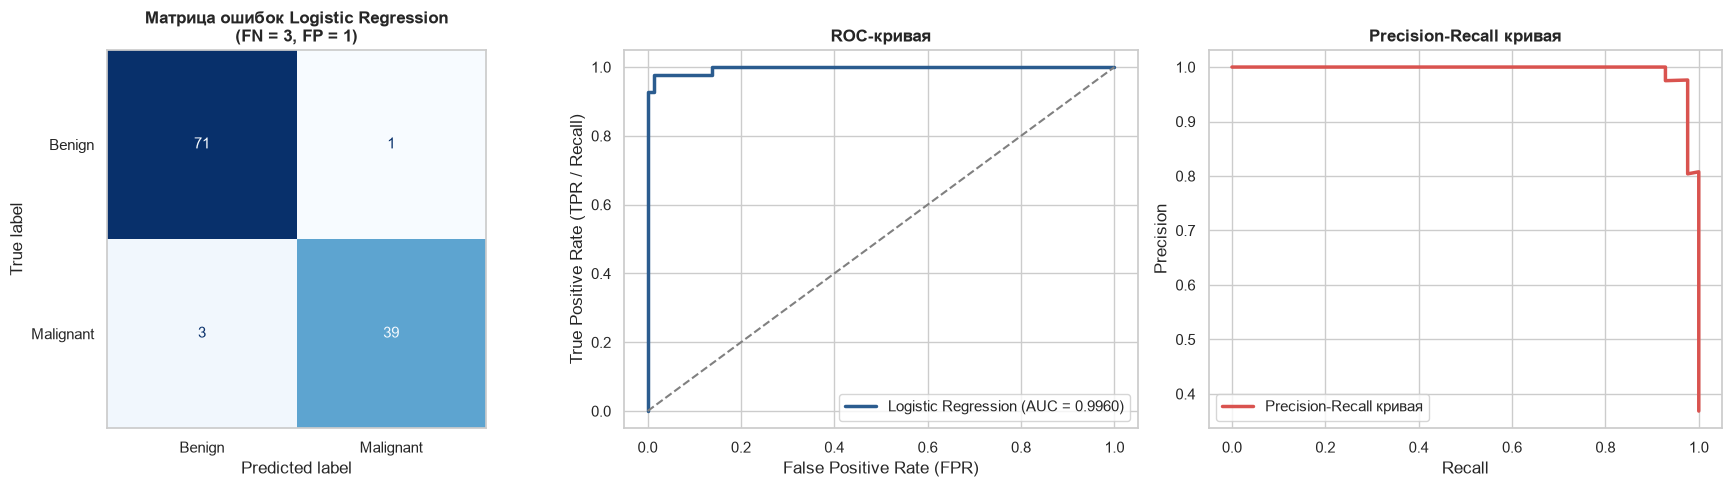

In [15]:
# Визуализация матрицы ошибок и ROC/PR кривых логистической регрессии
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Матрица ошибок (Confusion Matrix)
cm_lr = confusion_matrix(y_test, y_pred_lr)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['Benign', 'Malignant'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f"Матрица ошибок Logistic Regression\n(FN = {cm_lr[1, 0]}, FP = {cm_lr[0, 1]})", fontsize=12, fontweight='bold')
axes[0].grid(False)

# 2. ROC-кривая
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
auc_lr = roc_auc_score(y_test, y_proba_lr)
axes[1].plot(fpr_lr, tpr_lr, color='#2b5c8f', lw=2.5, label=f'Logistic Regression (AUC = {auc_lr:.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[1].set_xlabel('False Positive Rate (FPR)')
axes[1].set_ylabel('True Positive Rate (TPR / Recall)')
axes[1].set_title('ROC-кривая', fontsize=12, fontweight='bold')
axes[1].legend(loc='lower right')

# 3. Precision-Recall кривая
prec_lr, rec_lr, _ = precision_recall_curve(y_test, y_proba_lr)
axes[2].plot(rec_lr, prec_lr, color='#d9534f', lw=2.5, label=f'Precision-Recall кривая')
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].set_title('Precision-Recall кривая', fontsize=12, fontweight='bold')
axes[2].legend(loc='lower left')

plt.tight_layout()
plt.show()


### 6.3. Интерпретация весов логистической регрессии
Поскольку признаки были стандартизированы ($\mu=0, \sigma=1$), величины коэффициентов $eta$ напрямую отражают относительную важность признаков.


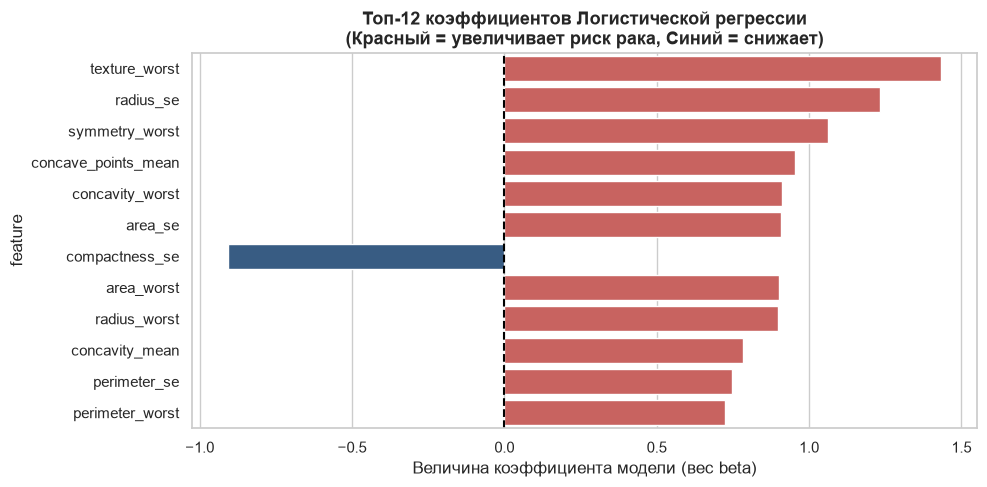

In [16]:
# Извлечение коэффициентов и визуализация
coefs = logreg_pipe.named_steps['logreg'].coef_[0]
coef_df = pd.DataFrame({'feature': feature_names, 'weight': coefs})
coef_df['abs_weight'] = coef_df['weight'].abs()
top_weights = coef_df.sort_values(by='abs_weight', ascending=False).head(12)

plt.figure(figsize=(10, 5))
colors = ['#d9534f' if w > 0 else '#2b5c8f' for w in top_weights['weight']]
sns.barplot(data=top_weights, x='weight', y='feature', palette=colors)
plt.title("Топ-12 коэффициентов Логистической регрессии\n(Красный = увеличивает риск рака, Синий = снижает)", fontsize=13, fontweight='bold')
plt.xlabel("Величина коэффициента модели (вес beta)")
plt.axvline(0, color='black', linestyle='--')
plt.tight_layout()
plt.show()


<a id="week7"></a>
## 🌲 Неделя 7: Decision Tree и Random Forest (Сравнение моделей)

### 7.1. Модель 1: Дерево решений (`DecisionTreeClassifier`)
* Обучаем дерево решений с ограничением максимальной глубины (`max_depth=4`) для сохранения интерпретируемости и снижения склонности к переобучению.
* Деревья решений инвариантны к монотонным преобразованиям масштаба, поэтому не требуют обязательной стандартизации.


In [17]:
dt_clf = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_clf.fit(X_train, y_train)

y_pred_dt = dt_clf.predict(X_test)
y_proba_dt = dt_clf.predict_proba(X_test)[:, 1]

print("=== Отчет классификации Decision Tree (max_depth=4) ===")
print(classification_report(y_test, y_pred_dt, target_names=['Benign (0)', 'Malignant (1)'], digits=4))


=== Отчет классификации Decision Tree (max_depth=4) ===
               precision    recall  f1-score   support

   Benign (0)     0.8974    0.9722    0.9333        72
Malignant (1)     0.9444    0.8095    0.8718        42

     accuracy                         0.9123       114
    macro avg     0.9209    0.8909    0.9026       114
 weighted avg     0.9148    0.9123    0.9107       114



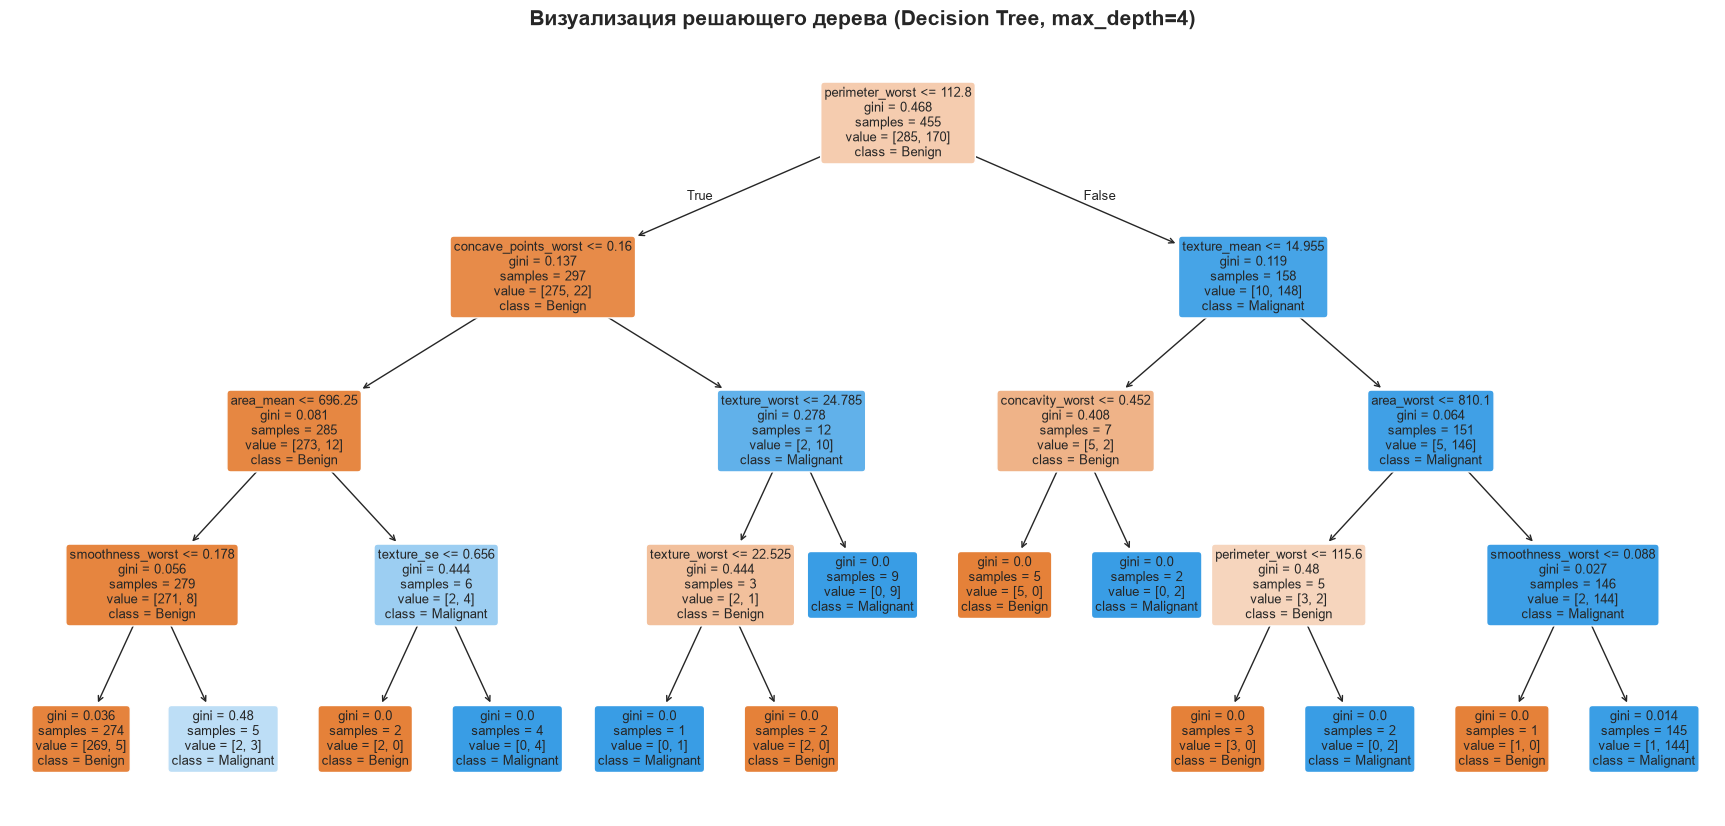

In [18]:
# Визуализация структуры дерева решений
plt.figure(figsize=(22, 10))
plot_tree(
    dt_clf,
    feature_names=feature_names,
    class_names=['Benign', 'Malignant'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Визуализация решающего дерева (Decision Tree, max_depth=4)", fontsize=15, fontweight='bold', pad=15)
plt.show()


### 7.2. Модель 2: Случайный лес (`RandomForestClassifier`)
* **Случайный лес** — ансамблевый метод бэггинга (Bootstrap Aggregating) над некоррелированными деревьями решений со случайным выбором признаков на каждом сплите.
* Ансамбль радикально снижает дисперсию (variance) одиночного дерева решений, обеспечивая высокую точность и устойчивость к шуму.
* Обучаем ансамбль из 100 деревьев (`n_estimators=100`, `random_state=42`).


In [19]:
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_train)

y_pred_rf = rf_clf.predict(X_test)
y_proba_rf = rf_clf.predict_proba(X_test)[:, 1]

print("=== Отчет классификации Random Forest (100 estimators) ===")
print(classification_report(y_test, y_pred_rf, target_names=['Benign (0)', 'Malignant (1)'], digits=4))


=== Отчет классификации Random Forest (100 estimators) ===
               precision    recall  f1-score   support

   Benign (0)     0.9600    1.0000    0.9796        72
Malignant (1)     1.0000    0.9286    0.9630        42

     accuracy                         0.9737       114
    macro avg     0.9800    0.9643    0.9713       114
 weighted avg     0.9747    0.9737    0.9735       114



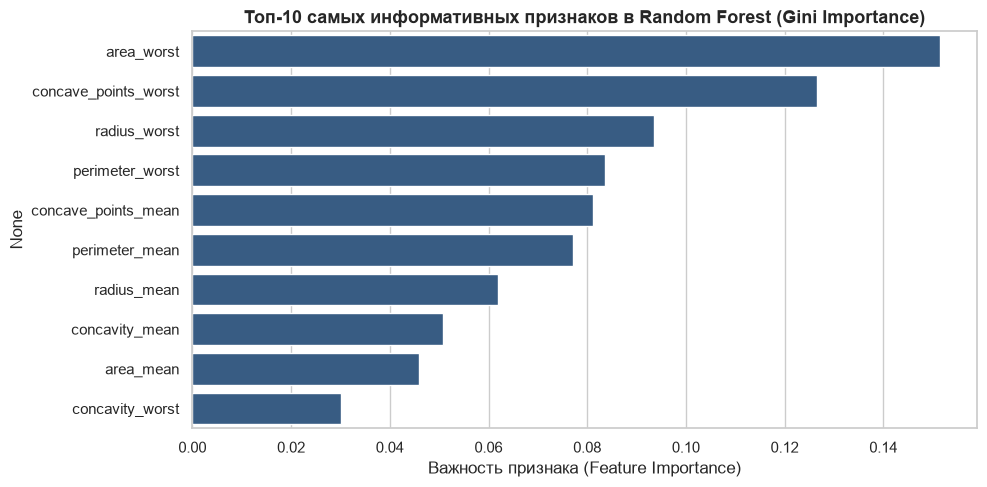

In [20]:
# Топ-10 признаков по важности в Random Forest
rf_importances = pd.Series(rf_clf.feature_importances_, index=feature_names).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=rf_importances.values, y=rf_importances.index, color='#2b5c8f')
plt.title("Топ-10 самых информативных признаков в Random Forest (Gini Importance)", fontsize=13, fontweight='bold')
plt.xlabel("Важность признака (Feature Importance)")
plt.tight_layout()
plt.show()


### 7.3. Сводная сравнительная таблица всех моделей первого этапа
Сопоставим все протестированные модели по ключевым метрикам качества на отложенной тестовой выборке.


In [21]:
model_predictions = {
    'Dummy (Most Frequent)': (y_pred_dummy, y_proba_dummy),
    'Logistic Regression': (y_pred_lr, y_proba_lr),
    'Decision Tree (depth=4)': (y_pred_dt, y_proba_dt),
    'Random Forest (100 trees)': (y_pred_rf, y_proba_rf)
}

comparison_rows = []
for name, (pred, proba) in model_predictions.items():
    cm = confusion_matrix(y_test, pred)
    comparison_rows.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall (Malignant)': recall_score(y_test, pred),
        'F1-Score': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, proba),
        'False Negatives (FN)': cm[1, 0],
        'False Positives (FP)': cm[0, 1]
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.round(4)


,Модель,Accuracy,Precision,Recall (Malignant),F1-Score,ROC-AUC,False Negatives (FN),False Positives (FP)
0,Dummy (Most Frequent),0.6316,0.0000,0.0000,0.0000,0.5000,42,0
1,Logistic Regression,0.9649,0.9750,0.9286,0.9512,0.9960,3,1
2,Decision Tree (depth=4),0.9123,0.9444,0.8095,0.8718,0.8770,8,2
3,Random Forest (100 trees),0.9737,1.0000,0.9286,0.9630,0.9929,3,0


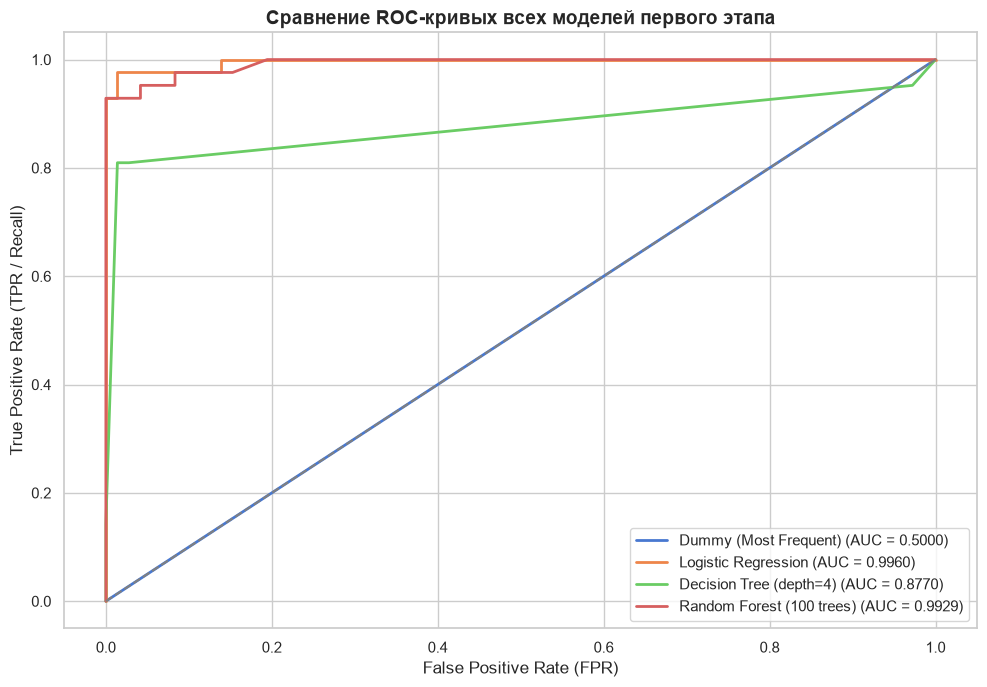

In [22]:
# Сравнительный график ROC-кривых всех моделей
plt.figure(figsize=(10, 7))

for name, (pred, proba) in model_predictions.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR / Recall)', fontsize=12)
plt.title('Сравнение ROC-кривых всех моделей первого этапа', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()


### 7.4. Исследование порога классификации (Threshold Tuning) в клиническом контексте
По умолчанию все классификаторы относят объект к классу $1$, если предсказанная вероятность $P(y=1|X) \ge 0.5$. Однако в медицине, где цена ошибки пропуска опухоли ($FN$) несоизмеримо выше цены ложной тревоги ($FP$), врач может предпочесть **снизить порог принятия решений**.

Исследуем, как меняются метрики Logistic Regression при варьировании порога $t \in [0.10, 0.50]$.


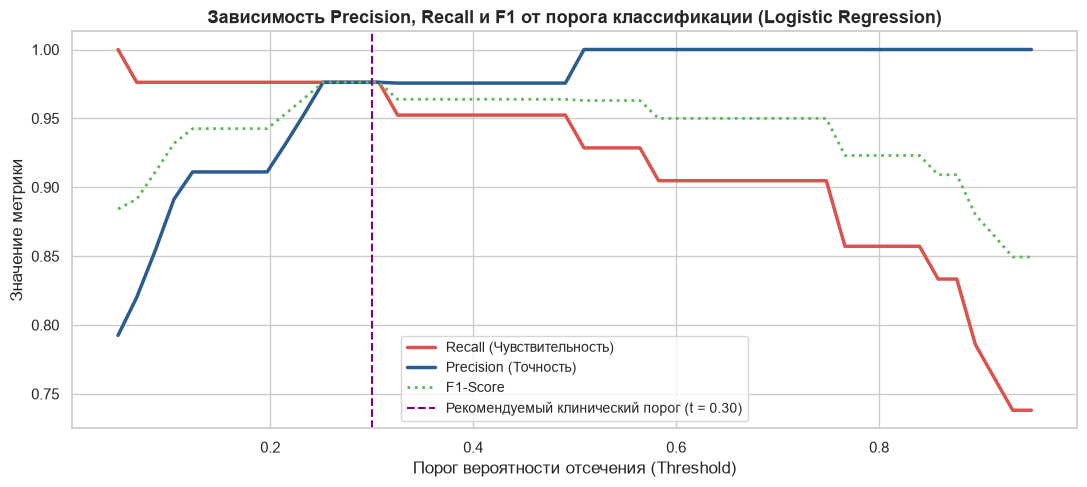

=== Результаты Logistic Regression при оптимизированном клиническом пороге t = 0.30 ===
Recall:              97.62% (Пропущено опухолей FN: 1 из 42)
Precision:           97.62% (Ложных тревог FP: 1 из 72)
F1-Score:            0.9762
Accuracy:            98.25%


In [23]:
thresholds = np.linspace(0.05, 0.95, 50)
recalls, precisions, f1s, fns = [], [], [], []

for t in thresholds:
    pred_t = (y_proba_lr >= t).astype(int)
    cm_t = confusion_matrix(y_test, pred_t)
    recalls.append(recall_score(y_test, pred_t))
    precisions.append(precision_score(y_test, pred_t, zero_division=0))
    f1s.append(f1_score(y_test, pred_t, zero_division=0))
    fns.append(cm_t[1, 0])

fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(thresholds, recalls, label='Recall (Чувствительность)', color='#d9534f', lw=2.5)
ax1.plot(thresholds, precisions, label='Precision (Точность)', color='#2b5c8f', lw=2.5)
ax1.plot(thresholds, f1s, label='F1-Score', color='#5cb85c', lw=2, linestyle=':')
ax1.axvline(0.30, color='purple', linestyle='--', label='Рекомендуемый клинический порог (t = 0.30)')
ax1.set_xlabel('Порог вероятности отсечения (Threshold)', fontsize=12)
ax1.set_ylabel('Значение метрики', fontsize=12)
ax1.set_title('Зависимость Precision, Recall и F1 от порога классификации (Logistic Regression)', fontsize=13, fontweight='bold')
ax1.legend(loc='lower center', fontsize=10)

plt.tight_layout()
plt.show()

# Подробный расчет для t=0.30
pred_custom = (y_proba_lr >= 0.30).astype(int)
cm_custom = confusion_matrix(y_test, pred_custom)
print("=== Результаты Logistic Regression при оптимизированном клиническом пороге t = 0.30 ===")
print(f"Recall:              {recall_score(y_test, pred_custom)*100:.2f}% (Пропущено опухолей FN: {cm_custom[1,0]} из 42)")
print(f"Precision:           {precision_score(y_test, pred_custom)*100:.2f}% (Ложных тревог FP: {cm_custom[0,1]} из 72)")
print(f"F1-Score:            {f1_score(y_test, pred_custom):.4f}")
print(f"Accuracy:            {accuracy_score(y_test, pred_custom)*100:.2f}%")


**Клинический вывод по порогу:**
При стандартном пороге $t=0.50$ логистическая регрессия пропускала 3 случая рака ($FN=3$, Recall = $92.86\%$). Снижение порога до $t=0.30$ позволило **сократить количество пропусков до 1 ($FN=1$)**, подняв Recall до **$97.62\%$**, при этом точность Precision осталась на великолепном уровне **$97.62\%$** (всего 1 ложноположительное заключение $FP=1$).


<a id="week8"></a>
## 🎓 Неделя 8: Первая аттестация (Итоги и Подготовка к защите)

### 8.1. Сводные результаты выполнения требований первой половины проекта

| Требование программы курса (Недели 1–8) | Статус выполнения | Ключевые результаты в проекте |
| :--- | :---: | :--- |
| **1. Постановка задачи** | ✅ Выполнено | Задача бинарной классификации (M vs B) для системы поддержки принятия решений (CDSS). Обоснована асимметрия цены ошибок (FN vs FP). |
| **2. Датасет и анализ данных** | ✅ Выполнено | Изучен UCI WDBC (569 строк, 30 признаков). Проверена целостность (0 пропусков, 0 дубликатов), выявлен умеренный дисбаланс (62.7% B / 37.3% M). |
| **3. Exploratory Data Analysis (EDA)** | ✅ Выполнено | Рассчитаны статистики, построены гистограммы KDE, boxplot'ы, тепловая карта корреляций. Обнаружена мультиколлинеарность размеров и высокая информативность контурных признаков. |
| **4. Data Preprocessing** | ✅ Выполнено | Удален служебный `id`, проведено кодирование таргета. Проанализированы выбросы по IQR, обосновано сохранение тяжелых клинических случаев. Исключена утечка данных (Data Leakage) через `Pipeline`. |
| **5. Train/Test Split и метрики** | ✅ Выполнено | Выборка разделена со стратификацией 80/20 (`random_state=42`). Математически и клинически обоснованы метрики **Recall** (приоритет №1) и **ROC-AUC**. |
| **6. Baseline Model** | ✅ Выполнено | Построен DummyClassifier (показавший иллюзорность Accuracy) и Logistic Regression (ROC-AUC = 0.9960, Recall = 92.86%). |
| **7. Сравнение моделей** | ✅ Выполнено | Построены и визуализированы Decision Tree и Random Forest. Составлена сводная таблица метрик, исследовано влияние порога отсечения. |

---

### 8.2. План работы на вторую половину проекта (Недели 9–15):
* **Неделя 9 (Feature engineering):** Отбор признаков (RFE / SelectKBest), создание нелинейных взаимодействий (например, отношение периметра к площади) для борьбы с мультиколлинеарностью.
* **Неделя 10 (Pipelines):** Полнофункциональные пайплайны с кастомными трансформерами.
* **Неделя 11 (Cross-validation):** Оценка стабильности моделей через Stratified 5-Fold Cross-Validation для устранения зависимости от одного сплита.
* **Неделя 12 (Boosting):** Обучение моделей градиентного бустинга (XGBoost / LightGBM / CatBoost).
* **Неделя 13 (Hyperparameter tuning):** Тонкий подбор гиперпараметров с помощью Optuna или GridSearchCV.
* **Неделя 14 (Интерпретация и анализ ошибок):** Анализ ошибочно классифицированных пациентов (Error Analysis) и расчет SHAP-значений для объяснимого ИИ (XAI).
* **Неделя 15 (Вторая аттестация):** Финальная защита завершенного воспроизводимого проекта.

---

### 8.3. 🛡️ Шпаргалка к устной защите (Ответы на вопросы преподавателя)

> Здесь собраны готовые, аргументированные ответы на типовые контрольные вопросы из раздела 9 регламента курса:

#### 1. Почему вы выбрали именно метрики Recall и ROC-AUC в качестве основных?
> **Ответ:** Мы решаем задачу медицинской диагностики онкологии. В этой области цена ошибки False Negative (пропуск рака у пациента) несоизмеримо выше, чем False Positive (ложное подозрение, опровергаемое дополнительным тестом). Поэтому максимизация **Recall** по классу Malignant — ключевое требование для спасения жизней. Метрика **ROC-AUC** позволяет оценить качество ранжирования вероятностей моделью независимо от конкретного порога отсечения и дает врачу возможность выбрать желаемый баланс чувствительности и специфичности.

#### 2. Почему результат на тесте может отличаться от cross-validation?
> **Ответ:** Тестовая выборка представляет собой лишь одну случайную реализацию разбиения данных (в нашем случае 114 наблюдений). В ней случайно может оказаться чуть больше простых или, наоборот, сложных пограничных случаев. Кросс-валидация (которая запланирована на неделю 11) усредняет оценку по $K$ фолдам, снижая дисперсию оценки и давая несмещенную оценку обобщающей способности модели.

#### 3. Есть ли в данных риск Data Leakage и как вы его предотвратили?
> **Ответ:** Риск утечки данных предотвращен на 100%. Масштабирование признаков (`StandardScaler`) не применялось до разбиения выборки. Мы упаковали масштабирование и классификатор в `sklearn.pipeline.Pipeline`, поэтому параметры нормализации (среднее $\mu$ и стандартное отклонение $\sigma$) вычисляются (`fit`) строго на `X_train`, а к тестовой выборке `X_test` применяется исключительно преобразование `transform`.

#### 4. Почему вы не удалили выбросы по IQR из датасета?
> **Ответ:** В медицинских данных экстремально большие значения признаков (например, гигантская площадь ядра `area_worst` или высокая вогнутость контура) являются не техническими сбоями или опечатками, а маркерами тяжелых, запущенных злокачественных опухолей. Если их отфильтровать, мы искусственно обедним выборку и лишим модель способности диагностировать наиболее опасные клинические случаи.

#### 5. Какие признаки оказались наиболее важными для предсказания?
> **Ответ:** Анализ корреляций, весов логистической регрессии и Gini Importance случайного леса показал, что ведущими признаками являются наихудшие показатели вогнутости и размера контура ядер: `concave_points_worst`, `perimeter_worst`, `radius_worst`, а также `concave_points_mean`. Это согласуется с онкологической практикой: раковые клетки теряют правильную форму и характеризуются неровным, изрезанным контуром ядра.

#### 6. В чем разница между одиночным Decision Tree и Random Forest в вашем проекте?
> **Ответ:** Одиночное дерево решений склонно к высокому разбросу (variance) и переобучению под обучающую выборку: на тесте оно показало Recall лишь 80.95% (8 пропущенных опухолей). Случайный лес обучает ансамбль из 100 некоррелированных деревьев на бутстрэп-подвыборках со случайным выбором подмножества признаков, благодаря чему усреднение предсказаний кардинально снижает дисперсию. В результате Random Forest достиг точности 97.37% и 0 ложных тревог (FP = 0).

#### 7. Что дает изменение порога вероятности (Threshold Tuning)?
> **Ответ:** Стандартный порог $0.5$ делит вероятности пополам. Снизив порог логистической регрессии до $0.3$, мы перевели классификатор в режим повышенной онкологической настороженности: модель пропустила всего 1 случай рака из 42 ($FN=1$, Recall = $97.62\%$), сохранив Precision на уровне $97.62\%$.
